# Setup

In [95]:
!pip install tiktoken

In [96]:
import tiktoken
import pandas as pd
import matplotlib.pyplot as plt
from transformers import  AutoTokenizer

In [97]:
gpt = tiktoken.get_encoding("o200k_base")

In [98]:
xlmr = AutoTokenizer.from_pretrained("xlm-roberta-base")

In [99]:
mbert  = AutoTokenizer.from_pretrained("bert-base-multilingual-cased")

In [100]:
qwen  = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B")

In [101]:
tokenizers={
    "GPT-4o": gpt,
    "XLM-R": xlmr,
    "mBERT": mbert,
    "Qwen": qwen,
}

# Data


In [102]:
sentences = [
    {"english": "The weather is nice today.", "urdu": "آج موسم اچھا ہے۔", "roman": "Aaj mausam acha hai."},
    {"english": "The food is ready.", "urdu": "کھانا تیار ہے۔", "roman": "Khana tayyar hai."},
    {"english": "I will go to the market tomorrow.", "urdu": "میں کل بازار جاؤں گی۔", "roman": "Main kal bazaar jaaungi."},
    {"english": "The model gave a wrong answer.", "urdu": "ماڈل نے غلط جواب دیا۔", "roman": "Model ne ghalat jawab diya."},
    {"english": "Artificial intelligence is changing how we learn and work.", "urdu": "مصنوعی ذہانت ہمارے سیکھنے اور کام کرنے کے طریقے بدل رہی ہے۔", "roman": "Masnooi zehanat hamare seekhne aur kaam karne ke tareeqe badal rahi hai."},
    {"english": "Please close the door.", "urdu": "براہ کرم دروازہ بند کر دیں۔", "roman": "Baraye meharbani darwaza band kar dein."},
    {"english": "My mother is making tea in the kitchen.", "urdu": "میری امی باورچی خانے میں چائے بنا رہی ہیں۔", "roman": "Meri ammi bawarchi khane mein chai bana rahi hain."},
    {"english": "How much does this book cost?", "urdu": "یہ کتاب کتنے کی ہے؟", "roman": "Yeh kitab kitne ki hai?"},
    {"english": "The train is two hours late.", "urdu": "ٹرین دو گھنٹے لیٹ ہے۔", "roman": "Train do ghante late hai."},
    {"english": "I could not sleep last night because of the heat.", "urdu": "گرمی کی وجہ سے میں کل رات سو نہیں سکی۔", "roman": "Garmi ki wajah se main kal raat so nahi saki."},
    {"english": "Children are playing cricket in the street.", "urdu": "بچے گلی میں کرکٹ کھیل رہے ہیں۔", "roman": "Bachay gali mein cricket khel rahe hain."},
    {"english": "The doctor said I should drink more water.", "urdu": "ڈاکٹر نے کہا کہ مجھے زیادہ پانی پینا چاہیے۔", "roman": "Doctor ne kaha ke mujhe zyada pani peena chahiye."},
    {"english": "Please send me the report by Friday.", "urdu": "براہ کرم جمعہ تک مجھے رپورٹ بھیج دیں۔", "roman": "Baraye meharbani Jumma tak mujhe report bhej dein."},
    {"english": "The internet has not been working since morning.", "urdu": "صبح سے انٹرنیٹ کام نہیں کر رہا۔", "roman": "Subah se internet kaam nahi kar raha."},
    {"english": "We need more data to train this model.", "urdu": "اس ماڈل کو تربیت دینے کے لیے ہمیں مزید ڈیٹا چاہیے۔", "roman": "Is model ko tarbiyat dene ke liye humein mazeed data chahiye."},
    {"english": "The retrieved documents did not contain the correct answer.", "urdu": "حاصل کردہ دستاویزات میں درست جواب موجود نہیں تھا۔", "roman": "Hasil karda dastavezaat mein durust jawab maujood nahi tha."},
    {"english": "Large language models sometimes produce confident but false statements.", "urdu": "بڑے لسانی ماڈل کبھی کبھی پُراعتماد مگر غلط بیانات دیتے ہیں۔", "roman": "Baray lisani model kabhi kabhi pur-aitmaad magar ghalat bayanat dete hain."},
    {"english": "Pakistan has many beautiful mountains in the north.", "urdu": "پاکستان کے شمال میں بہت سے خوبصورت پہاڑ ہیں۔", "roman": "Pakistan ke shumal mein bohat se khoobsurat pahar hain."},
    {"english": "If it rains tomorrow, we will stay at home and watch a movie.", "urdu": "اگر کل بارش ہوئی تو ہم گھر پر رہ کر فلم دیکھیں گے۔", "roman": "Agar kal barish hui to hum ghar par reh kar film dekhenge."},
    {"english": "Learning to code is difficult at first, but it becomes easier with daily practice.", "urdu": "کوڈنگ سیکھنا شروع میں مشکل ہوتا ہے، لیکن روزانہ مشق سے آسان ہو جاتا ہے۔", "roman": "Coding seekhna shuru mein mushkil hota hai, lekin rozana mashq se aasaan ho jata hai."},
]

# Count tokens

In [103]:
rows = []

def count_tokens(text,name, tok):
  if name == "GPT-4o":
    return len(tok.encode(text))
  else:
    return len(tok.encode(text, add_special_tokens=False) )

for name,tok in tokenizers.items():
  for s in sentences:
    for lang in ["english", "urdu", "roman"]:
      rows.append({"tokenizer": name, "language": lang , "tokens": count_tokens(s[lang], name, tok)})
print(len(rows))

240


# Results

In [104]:
df=pd.DataFrame(rows)
print(df.head())
table = df.groupby(["tokenizer","language"])["tokens"].mean().unstack()
table["urdu_tax"] = table["urdu"] / table["english"]
table["roman_tax"] = table["roman"] / table["english"]
print(table)

  tokenizer language  tokens
0    GPT-4o  english       6
1    GPT-4o     urdu       7
2    GPT-4o    roman       7
3    GPT-4o  english       5
4    GPT-4o     urdu       5
language   english  roman   urdu  urdu_tax  roman_tax
tokenizer                                            
GPT-4o        8.90   14.3  12.70  1.426966   1.606742
Qwen          8.95   16.2  25.85  2.888268   1.810056
XLM-R         9.30   13.1   9.25  0.994624   1.408602
mBERT         9.35   15.3  14.85  1.588235   1.636364


# Chart

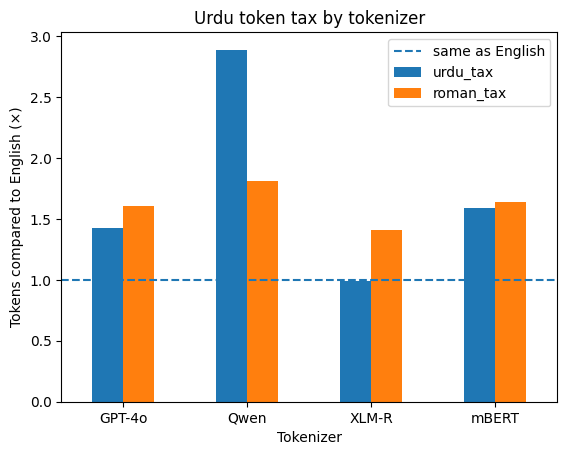

In [105]:
table[["urdu_tax", "roman_tax"]].plot(kind="bar")
plt.axhline(1, linestyle="--",label="same as English")
plt.title("Urdu token tax by tokenizer")
plt.xlabel("Tokenizer")
plt.ylabel("Tokens compared to English (×)")
plt.legend()
plt.xticks(rotation=0)
plt.savefig("token_tax.png", dpi=200, bbox_inches="tight")
plt.show()